# Senate Monte Carlo: S-M0 (baseline), S-M1 and S-M2 (experiments)

Simulated margins are centered on the **Stage 2 blend** (fixed weights 37/54/9 with polls, 65/0/35 without). Their
errors are estimated from the blend's own out-of-sample residuals, 2016–2024 (the years with expert ratings):

- **S-M0:** a national Student-t error (ν = 5), one draw per simulation. The national SD is regularized toward a
  fixed 3-point prior worth 2 pseudo-elections. Each race also gets an independent t error.
- **S-M1:** the same, but with separate race scales for polled and unpolled races, each shrunk toward the pooled
  scale with 30 pseudo-races.
- **S-M2:** S-M0 plus a regional t error, one draw per region per simulation, using the 10 political regions in
  `data/reference/regional_stage2.csv`. The regional variance is the same-region minus different-region
  co-movement of race deviations, shrunk toward 0 with 3 pseudo-elections. It is taken out of the race variance, so
  each race's total error variance stays S-M0's.

Nothing is tuned on the backtest. Code: `src/senate/simulation/` (Senate-only).

**Polling sources differ:** the historical residuals use 30-day RCP means, while 2026 uses FiftyPlusOne averages.
Their errors may differ, so the 2026 polled-race scale is borrowed, not measured.

In [1]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))
from senate import stage1
from senate.simulation import MODELS, calibration, chamber, errors, track

pd.set_option("display.width", 200)
STAGE1_CONFIG = stage1.SENATE_S1   # or stage1.SENATE_S0
PRIMARY = "S-M0"                   # the baseline; S-M1 is the experiment
N_SIMS = 40_000
SEED = 0

## 1. Out-of-sample blend residuals (actual − blend), 2016–2024

In [2]:
oos = calibration.blend_out_of_sample(STAGE1_CONFIG)
display(oos.groupby("year")["residual"].agg(n="size", mean="mean", sd="std", mae=lambda r: r.abs().mean()).round(2))
display(Markdown("**Polled vs unpolled** (S-M1's groups). Polling availability tracks competitiveness: unpolled "
                 "races are mostly safe seats (larger |prediction|), and few of them are competitive ex ante."))
calibration.polling_group_diagnostics(oos).round(2)

,n,mean,sd,mae
year,,,,
2016,32,-4.06,9.79,7.05
2018,34,0.44,4.21,3.38
2020,34,-4.34,5.23,5.13
2022,33,0.88,5.68,4.28
2024,33,-2.27,4.51,4.06


**Polled vs unpolled** (S-M1's groups). Polling availability tracks competitiveness: unpolled races are mostly safe seats (larger |prediction|), and few of them are competitive ex ante.

,n,bias,mae,sd,n_competitive_ex_ante,bias_competitive,mean_abs_prediction
polled,109.0,-1.92,4.35,5.36,48.0,-1.81,13.80
unpolled,57.0,-1.75,5.54,8.27,3.0,2.34,27.53


## 2. Chronological backtest, 2018–2024

Each test year's SDs come from the residuals of earlier years only: 2018 is fit on 2016 alone, so its national SD is
mostly the prior. Seat counts are D wins on the year's **matched panel**, the scored D-vs-R races only, never Senate
totals. Independent-vs-R and imputed races are never in a historical panel.

In [3]:
backtests = {m: calibration.backtest(oos, model=m, n_sims=N_SIMS, seed=SEED) for m in MODELS}
display(Markdown("**SDs used for each test year**"))
display(pd.concat({m: bt["sds"] for m, bt in backtests.items()}, names=["model", "test_year"]))
display(Markdown("**Brier, coverage and interval width** (nominal coverage = the level)"))
display(pd.concat({m: bt["metrics"] for m, bt in backtests.items()}, names=["model", "test_year"]).round(3))
display(Markdown("**Matched-panel D wins:** actual vs simulated, with the actual count's mid-rank percentile"))
pd.concat({m: bt["seats"] for m, bt in backtests.items()}, names=["model", "test_year"]).round(3)

**SDs used for each test year**

national      race train_years race_polled race_unpolled  regional
model test_year                                                                    
S-M0  2018       3.388793  9.790024   2016-2016         NaN           NaN       NaN
      2020       2.942917  7.453549   2016-2018         NaN           NaN       NaN
      2022       3.270321   6.78003   2016-2020         NaN           NaN       NaN
      2024       3.006746  6.524971   2016-2022         NaN           NaN       NaN
S-M1  2018       3.388793  9.790024   2016-2016    8.683371     11.064416       NaN
      2020       2.942917  7.453549   2016-2018    6.293863      9.074838       NaN
      2022       3.270321   6.78003   2016-2020    5.673866      8.265994       NaN
      2024       3.006746  6.524971   2016-2022     5.53338      7.944873       NaN
S-M2  2018       3.388793  9.389304   2016-2016         NaN           NaN  2.772282
      2020       2.942917  7.017791   2016-2018         NaN           NaN  2.511176
      2022       3.270321  6.451453   2016-2020         NaN           NaN  2.085081
      2024       3.006746  6.232108   2016-2022         NaN           NaN  1.932893

**Brier, coverage and interval width** (nominal coverage = the level)

n  brier  n_competitive  brier_competitive  coverage_0.5  coverage_0.8  coverage_0.9  coverage_0.95  width_0.5  width_0.8  width_0.9  width_0.95
model test_year                                                                                                                                                      
S-M0  2018        34.0  0.060            9.0              0.091         0.882         1.000         1.000          1.000     12.013     24.077     32.490      41.029
      2020        34.0  0.055           10.0              0.113         0.529         0.824         0.941          0.971      9.364     18.721     25.239      31.784
      2022        33.0  0.039            9.0              0.140         0.636         0.909         0.939          0.970      8.854     17.675     23.771      29.860
      2024        33.0  0.031           11.0              0.085         0.667         0.909         1.000          1.000      8.436     16.842     22.642      28.419
      pooled     134.0  0.046           39.0              0.106         0.679         0.910         0.970          0.985      9.682     19.360     26.078      32.827
S-M1  2018        34.0  0.059            9.0              0.091         0.853         1.000         1.000          1.000     11.376     22.775     30.701      38.743
      2020        34.0  0.055           10.0              0.110         0.588         0.882         0.912          0.941      9.354     18.721     25.230      31.781
      2022        33.0  0.038            9.0              0.137         0.576         0.909         0.939          0.970      8.560     17.061     22.941      28.800
      2024        33.0  0.030           11.0              0.082         0.667         0.879         0.970          1.000      8.637     17.247     23.196      29.150
      pooled     134.0  0.046           39.0              0.104         0.672         0.918         0.955          0.978      9.495     18.978     25.553      32.166
S-M2  2018        34.0  0.060            9.0              0.092         0.882         1.000         1.000          1.000     12.239     24.352     32.685      41.002
      2020        34.0  0.055           10.0              0.113         0.529         0.824         0.941          0.971      9.565     18.982     25.346      31.707
      2022        33.0  0.039            9.0              0.139         0.636         0.909         0.939          0.970      9.032     17.882     23.907      29.811
      2024        33.0  0.032           11.0              0.086         0.667         0.879         1.000          1.000      8.600     17.063     22.862      28.546
      pooled     134.0  0.046           39.0              0.107         0.679         0.903         0.970          0.985      9.875     19.601     26.242      32.820

**Matched-panel D wins:** actual vs simulated, with the actual count's mid-rank percentile

panel_races  actual_dem_wins  median   p10   p90   p05   p95  seat_percentile
model test_year                                                                               
S-M0  2018              34.0             23.0    22.0  19.0  25.0  18.0  26.0            0.682
      2020              34.0             13.0    16.0  13.0  18.0  12.0  19.0            0.098
      2022              33.0             15.0    13.0  11.0  16.0  10.0  17.0            0.811
      2024              33.0             19.0    19.0  17.0  21.0  16.0  22.0            0.517
S-M1  2018              34.0             23.0    22.0  19.0  25.0  18.0  26.0            0.678
      2020              34.0             13.0    16.0  13.0  18.0  12.0  19.0            0.088
      2022              33.0             15.0    13.0  11.0  16.0  10.0  17.0            0.821
      2024              33.0             19.0    19.0  17.0  21.0  16.0  22.0            0.503
S-M2  2018              34.0             23.0    22.0  19.0  25.0  18.0  26.0            0.676
      2020              34.0             13.0    16.0  13.0  19.0  12.0  19.0            0.108
      2022              33.0             15.0    13.0  11.0  16.0  10.0  17.0            0.807
      2024              33.0             19.0    19.0  16.0  21.0  16.0  22.0            0.515

In [4]:
display(Markdown("**S-M1 by polling group** (pooled over test years): coverage and Brier within each group"))
races = pd.concat({m: bt["races"] for m, bt in backtests.items()}, names=["model"]).reset_index(level=0)
races.groupby(["model", "polling_available"]).apply(calibration.summarize, include_groups=False).round(3)

**S-M1 by polling group** (pooled over test years): coverage and Brier within each group

n  brier  n_competitive  brier_competitive  coverage_0.5  coverage_0.8  coverage_0.9  coverage_0.95  width_0.5  width_0.8  width_0.9  width_0.95
model polling_available                                                                                                                                                     
S-M0  False              47.0  0.005            3.0              0.070         0.638         0.894         0.957          0.957      9.334     18.637     25.089      31.579
      True               87.0  0.069           36.0              0.109         0.701         0.920         0.977          1.000      9.869     19.750     26.612      33.501
S-M1  False              47.0  0.005            3.0              0.073         0.723         0.936         0.957          0.979     10.860     21.728     29.317      37.013
      True               87.0  0.068           36.0              0.106         0.644         0.908         0.954          0.977      8.758     17.492     23.520      29.547
S-M2  False              47.0  0.005            3.0              0.071         0.638         0.872         0.957          0.957      9.528     18.887     25.272      31.624
      True               87.0  0.069           36.0              0.109         0.701         0.920         0.977          1.000     10.062     19.987     26.766      33.466

## 3. 2026

- **Centers:** the Stage 2 blend for the 32 races with a Democratic nominee.
- **Independent races:** NE (Osborn), ID and SD have an independent against a Republican and no Democrat. Their
  center is the expert-rating margin alone, since the ratings rate the actual matchup (positive = independent
  ahead). It is not the D-vs-R blend.
- **Seats:** a non-Republican win in those races is a **new independent** with unknown caucus, never a D seat.
- **Holdovers:** 34 D-aligned seats (32 Democrats plus King and Sanders) and 31 Republicans.

In [5]:
point = chamber.forecast_points(STAGE1_CONFIG)
display(point.loc[point["seat_type"] != "dem_nominee",
                  ["state", "class", "seat_type", "center", "center_source", "margin_fundamentals", "matchup_note"]]
        .round(1))
n_dem_nominee = int((point["seat_type"] == "dem_nominee").sum())
print(f"D-aligned range: {chamber.DEM_ALIGNED_HOLDOVER} to {chamber.DEM_ALIGNED_HOLDOVER + n_dem_nominee} "
      f"({n_dem_nominee} races with a Democratic nominee; the {len(point) - n_dem_nominee} independent-only races "
      "can add only new independents)")

,state,class,seat_type,center,center_source,margin_fundamentals,matchup_note
8,ID,2,independent_only,-31.0,expert ratings only (independent-vs-R heuristic),-28.4,no named independent opponent in senate_fec.cs...
20,NE,2,independent_only,-8.5,expert ratings only (independent-vs-R heuristic),-13.4,NaN
29,SD,2,independent_only,-31.0,expert ratings only (independent-vs-R heuristic),-21.7,no named independent opponent in senate_fec.cs...


D-aligned range: 34 to 66 (32 races with a Democratic nominee; the 3 independent-only races can add only new independents)


In [6]:
results = {}
for m in MODELS:
    sds, details = errors.estimate_error_sds(oos, m)  # all of 2016-2024
    sims, counts = chamber.simulate_2026(point, sds, n_sims=N_SIMS, seed=SEED)
    assert counts["dem_aligned"].between(chamber.DEM_ALIGNED_HOLDOVER,
                                         chamber.DEM_ALIGNED_HOLDOVER + n_dem_nominee).all()
    results[m] = {"sds": sds, "details": details, "sims": sims, "counts": counts}
display(pd.concat({m: r["details"] for m, r in results.items()}, names=["model"]).round(2))
display(Markdown("**Senate control** (VP is a Republican, so 50-50 is Republican). Caucus scenarios for the new "
                 "independents:"))
display(pd.DataFrame({m: chamber.control(r["counts"]) for m, r in results.items()}).round(3))
display(Markdown("**Seats by category** (mean and 10th/50th/90th percentiles)"))
pd.concat({m: r["counts"].describe(percentiles=[0.1, 0.5, 0.9]).T[["mean", "10%", "50%", "90%", "min", "max"]]
           for m, r in results.items()}, names=["model"]).round(1)

observations  raw_sd    sd                                   regularization
model component                                                                                   
S-M0  national                    5    2.88  2.91                  prior sd 3 x 2 pseudo-elections
      race (pooled)             166    6.18  6.18                                             none
S-M1  national                    5    2.88  2.91                  prior sd 3 x 2 pseudo-elections
      race (pooled)             166    6.18  6.18                             the shrinkage target
      race (polled)             109    5.04  5.30            shrunk to pooled with 30 pseudo-races
      race (unpolled)            57    7.91  7.36            shrunk to pooled with 30 pseudo-races
S-M2  national                    5    2.88  2.91                  prior sd 3 x 2 pseudo-elections
      race (pooled)             166    6.18  5.87               pooled minus the regional variance
      regional                    5    2.42  1.91  zero prior x 3 pseudo-elections; truncated at 0

**Senate control** (VP is a Republican, so 50-50 is Republican). Caucus scenarios for the new independents:

,S-M0,S-M1,S-M2
P(D control): new independents with R or neither,0.700,0.712,0.696
P(D control): new independents with D,0.708,0.724,0.704
P(R seats >= 50),0.292,0.276,0.296


**Seats by category** (mean and 10th/50th/90th percentiles)

mean   10%   50%   90%   min   max
model                                                     
S-M0  dem_party         49.4  47.0  50.0  52.0  38.0  59.0
      dem_aligned       51.4  49.0  52.0  54.0  40.0  61.0
      new_independents   0.1   0.0   0.0   0.0   0.0   2.0
      gop               48.5  46.0  48.0  51.0  37.0  60.0
S-M1  dem_party         49.6  47.0  50.0  52.0  38.0  59.0
      dem_aligned       51.6  49.0  52.0  54.0  40.0  61.0
      new_independents   0.1   0.0   0.0   1.0   0.0   2.0
      gop               48.3  46.0  48.0  51.0  38.0  60.0
S-M2  dem_party         49.4  47.0  50.0  52.0  37.0  60.0
      dem_aligned       51.4  49.0  52.0  54.0  39.0  62.0
      new_independents   0.1   0.0   0.0   0.0   0.0   2.0
      gop               48.5  46.0  48.0  51.0  37.0  61.0

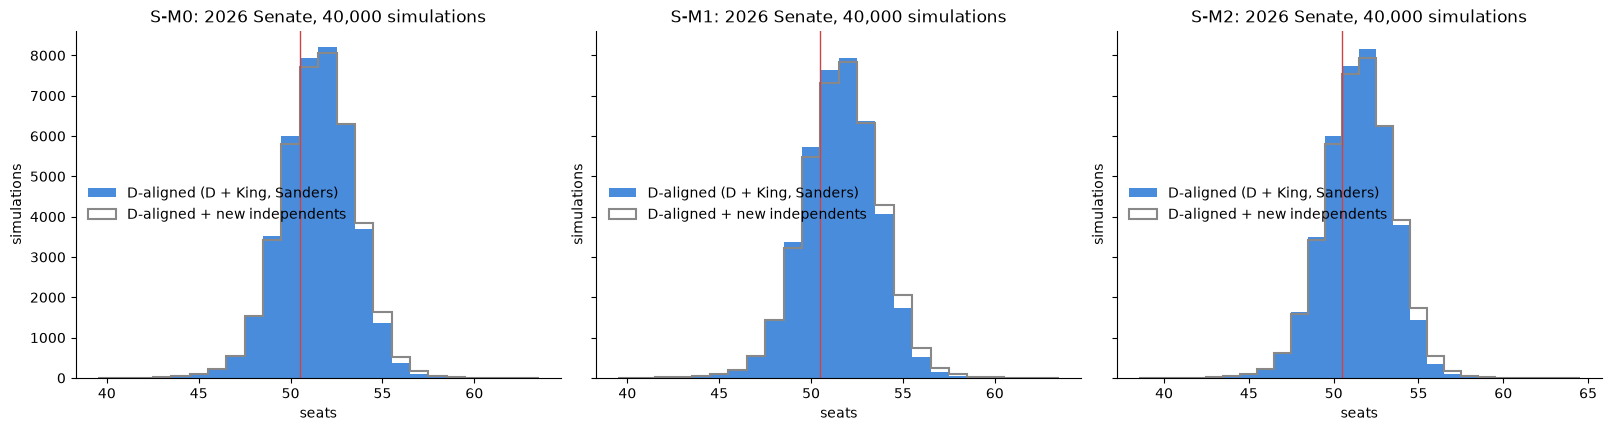

In [7]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(16, 4.2), sharey=True, layout="constrained")
for ax, m in zip(axes, MODELS):
    chamber.plot_seat_distribution(results[m]["counts"], ax, title=f"{m}: 2026 Senate, {N_SIMS:,} simulations")
plt.show()

In [8]:
p_win = pd.DataFrame({m: (r["sims"] > 0).mean(axis=0) for m, r in results.items()})
table = point[["state", "class", "seat_type", "center", "polling_available"]].join(p_win)
display(Markdown("**Races between 5% and 95% for the non-Republican** (P = share of draws > 0: D, or the "
                 "independent in independent-only races)"))
table[table[PRIMARY].between(0.05, 0.95)].sort_values(PRIMARY).round(3)

**Races between 5% and 95% for the non-Republican** (P = share of draws > 0: D, or the independent in independent-only races)

,state,class,seat_type,center,polling_available,S-M0,S-M1,S-M2
28,SC,2,dem_nominee,-9.239,False,0.075,0.100,0.075
20,NE,2,independent_only,-8.500,False,0.091,0.118,0.092
5,FL,3,dem_nominee,-5.465,True,0.180,0.155,0.184
7,IA,2,dem_nominee,-1.104,True,0.426,0.416,0.428
0,AK,2,dem_nominee,-0.629,True,0.458,0.453,0.457
10,KS,2,dem_nominee,-0.532,True,0.462,0.457,0.463
31,TX,2,dem_nominee,1.631,True,0.608,0.621,0.607
24,OH,3,dem_nominee,1.668,True,0.615,0.628,0.614
15,MI,2,dem_nominee,6.980,True,0.871,0.896,0.867
14,ME,2,dem_nominee,8.010,True,0.901,0.923,0.899


## 4. Congress-track Senate rows

- **Candidate names:** the model's nominee slots in `senate_fec.csv` (D and R). In AK, with two Dan Sullivans on the
  ballot, the slot is the incumbent, Dan S. For an independent-only race, the name is `ind_name`, or else the only
  Independent on the 2026 ballot list.
  - ID has two independents (Achilles, Fleming) and no slot, so its independent is unresolved. That only matters if
    the independent were the predicted winner, and `track_table` refuses that case.
- **Party:** D, R or I (I = an independent-only race's non-Republican). The predicted winner is the side with more
  than half the draws. `win_probability` is that side's share of draws.
- **Files:** one per model (`congress_track_senate_2026_<model>.csv`). The primary model's is also written as
  `congress_track_senate_2026.csv`.

In [9]:
named = track.resolve_candidates(point, pd.read_csv(track.NOMINEES_PATH), pd.read_csv(track.BALLOT_PATH))
display(named.loc[named["seat_type"] != "dem_nominee", ["state", "seat_type", "gop_candidate", "ind_candidate",
                                                        "independent_resolution"]])
template = pd.read_csv(track.TRACK_TEMPLATE_PATH)
tracks = {}
for m in MODELS:
    tracks[m] = track.track_table(named, results[m]["sims"], template)
    path = track.TRACK_OUTPUT_PATH.with_name(f"congress_track_senate_2026_{m.lower().replace('-', '')}.csv")
    tracks[m].to_csv(path, index=False)
    print(f"{m}: {len(tracks[m])} Senate rows -> {path.relative_to(ROOT)}")
tracks[PRIMARY].to_csv(track.TRACK_OUTPUT_PATH, index=False)
print(f"primary ({PRIMARY}) -> {track.TRACK_OUTPUT_PATH.relative_to(ROOT)}")
display(pd.DataFrame({m: t["predicted_winner_party"].value_counts() for m, t in tracks.items()}).fillna(0).astype(int))
side = tracks[PRIMARY].set_index("race_id").join(pd.DataFrame(
    {m: t.set_index("race_id")["win_probability"] for m, t in tracks.items() if m != PRIMARY}))
side.sort_values("win_probability").head(12).round(3)

,state,seat_type,gop_candidate,ind_candidate,independent_resolution
8,ID,independent_only,Jim Risch,NaN,unresolved: 2 independents on the ballot (Todd...
20,NE,independent_only,Pete Ricketts,Dan Osborn,senate_fec.csv ind_name
29,SD,independent_only,Mike Rounds,Brian Bengs,the only Independent on the ballot


S-M0: 35 Senate rows -> data/processed/senate/congress_track_senate_2026_sm0.csv
S-M1: 35 Senate rows -> data/processed/senate/congress_track_senate_2026_sm1.csv
S-M2: 35 Senate rows -> data/processed/senate/congress_track_senate_2026_sm2.csv
primary (S-M0) -> data/processed/senate/congress_track_senate_2026.csv


,S-M0,S-M1,S-M2
predicted_winner_party,,,
R,18,18,18
D,17,17,17


,chamber,predicted_winner_party,candidate_name,win_probability,S-M1,S-M2
race_id,,,,,,
KS-SEN,Senate,R,Roger Marshall,0.538,0.543,0.537
AK-SEN,Senate,R,Dan S. Sullivan,0.542,0.547,0.543
IA-SEN,Senate,R,Ashley Hinson,0.574,0.584,0.572
TX-SEN,Senate,D,James Talarico,0.608,0.621,0.607
OH-SEN,Senate,D,Sherrod Brown,0.615,0.628,0.614
FL-SEN,Senate,R,Ashley Moody,0.820,0.845,0.816
MI-SEN,Senate,D,Abdul El-Sayed,0.871,0.896,0.867
ME-SEN,Senate,D,Troy Jackson,0.901,0.923,0.899
NE-SEN,Senate,R,Pete Ricketts,0.909,0.882,0.908


## Notes

- **Primary model:** S-M0. S-M1 only splits the race scale, and the split partly tracks how competitive the races are
  (§1), not polling alone.
- **Independent-race scale:** these races use race scales estimated on D-vs-R blend residuals. With expert-only
  centers the true error is likely larger, so their probabilities are probably too confident.
- **S-M2:** the regional SD comes from 5 elections with about 3 races per region-year, so it's a rough sensitivity
  estimate, not a measured structure.
- **SC:** `senate_incumbency.csv` codes SC as a Republican incumbent seat (S1's +2.5 term applies). But the 2026
  Republican nominee in both the ballot list and FEC is Darline Graham, a new candidate, not Lindsey Graham. Check the
  incumbency coding.
- **Not modeled:** state-level correlation beyond regions, and candidate-specific errors.